**ANOMALY DETECTION OC-SVM**

In [3]:
import digitalhub as dh
import zipfile
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

PROJECT_NAME = "floods"
project = dh.get_project(PROJECT_NAME)
print(f"Project: {project.name}")

Project: floods


**SETUP PARAMETERS**

In [10]:
job_name = "attn_20per_w"
dataset_standard = "Standard"
dataset_anomalies = "Floods_Anomalies_v3_crop_norm"
moco_version = "v2"

parameters = {
    "job_name": job_name,                          
    "dataset_standard": dataset_standard,
    "dataset_anomalies": dataset_anomalies,         
    "moco_version": moco_version, 
    "old_vectors": "attn_0per_w", 
    "ocsvm_nu": 0.05,                       
    "ocsvm_gamma": "scale", 
    "min_flood_area": 20.0,
    "moco_attn": True,                 
    
    "simple_proj": False,                          
    "attn": False,                                  
    "hidden_channels_dim": 64,
    "pool_grid": 4,
    "moco_dim": 128,
    "moco_k": 4096,
    "moco_m": 0.999,
    "moco_t": 0.07,
    "patch_size": 256,
    "n_images1": 4, "n_channels1": 2,       # sar
    "n_images2": 4, "n_channels2": 10,      # ottico       
    "standardize": True,                    
    "batch_size": 16,
    "workers": 0,
}

volumes = [
    {
        "volume_type": "ephemeral",
        "name": "volume-spazio-dati",
        "mount_path": "/data",
        "spec": {"size": "200Gi"}
    }
]

**BUILD ENVIRONMENT**

In [11]:
ocsvm_func = project.new_function(
    name=f'ocsvm_w',
    kind="python",
    python_version="PYTHON3_10",
    code_src="../src/",
    handler="anomaly:ad_ocsvm",
    image="harbor.atlas.fbk.eu/rsde/rsde-platform-floods-floodsimagev3:9b7e2",
)

**TRAINING**

In [12]:
resources = {"cpu": "4", "mem": "20Gi"}

run_ad = ocsvm_func.run(
    action="job",
    parameters=parameters,
    volumes=volumes,
    resources = resources,
    profile="1xv100-shared",
    local_execution=False,
    wait=True
)

print(f"Run anomaly detection ocsvm: {run_ad.id}")

2026-10-23 14:15:14,066 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run dffaed39238e4fd28cd2c8a9e7f202fd to finish...
2026-10-23 14:15:19,073 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run dffaed39238e4fd28cd2c8a9e7f202fd to finish...
2026-10-23 14:15:24,083 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run dffaed39238e4fd28cd2c8a9e7f202fd to finish...
2026-10-23 14:15:29,092 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run dffaed39238e4fd28cd2c8a9e7f202fd to finish...
2026-10-23 14:15:34,101 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run dffaed39238e4fd28cd2c8a9e7f202fd to finish...
2026-10-23 14:15:39,110 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run dffaed39238e4fd28cd2c8a9e7f202fd to finish...
2026-10-23 14:15:44,220 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run dffaed39238e4fd28cd2c8a9e7f202fd to finish...
2026-10-23 14

Run anomaly detection ocsvm: dffaed39238e4fd28cd2c8a9e7f202fd


In [13]:
RESULTS_DIR = "/tmp/anomaly_results_ocsvm"

zip_path = project.get_artifact(f"anomaly_results_ocsvm_{job_name}").download("/tmp/anomaly_results_ocsvm.zip", overwrite=True)
with zipfile.ZipFile(zip_path) as z:
    z.extractall(RESULTS_DIR)
with open(f"{RESULTS_DIR}/anomaly_results.json") as f:
    results = json.load(f)

df = pd.read_csv(f"{RESULTS_DIR}/scores.csv")                    
score_normal = df[df.label == 0]['score']
score_anom = df[df.label == 1]['score']

print(f"n_fit: {results['n_fit']} | n_thr: {results['n_thr']} | n_normali: {results['n_normali']} | n_anomale: {results['n_anomale']}", "\n")
print(f"nu: {results['ocsvm']['nu']} | gamma: {results['ocsvm']['gamma']} | dim: {results['ocsvm']['dim']} | frac_outside_fit: {results['ocsvm']['frac_outside_fit']}") 
print(f"min_flood_area = {results['min_flood_area']:.3f} ")
print(f"score normali: {score_normal.mean():.4f} ± {score_normal.std():.4f}")
print(f"score anomale: {score_anom.mean():.4f} ± {score_anom.std():.4f}", "\n")
print(f"AUROC: {results['auroc']:.3f}")

df_rules = pd.DataFrame(results['rules']).T
df_rules

n_fit: 2072 | n_thr: 500 | n_normali: 1085 | n_anomale: 1085 

nu: 0.05 | gamma: scale | dim: 256 | frac_outside_fit: 0.061293436293436296
min_flood_area = 20.000 
score normali: 1.1543 ± 0.9326
score anomale: 0.0775 ± 0.9791 

AUROC: 0.802


,soglia,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
FA 5%,-1.048338,194.0,44.0,891.0,1041.0,0.040553,0.821198,0.178802,0.815126,0.293273
FA 10%,-0.401145,330.0,88.0,755.0,997.0,0.081106,0.695853,0.304147,0.789474,0.439122
FA 15%,0.026913,458.0,135.0,627.0,950.0,0.124424,0.577880,0.422120,0.772344,0.545888
FA 20%,0.426357,622.0,199.0,463.0,886.0,0.183410,0.426728,0.573272,0.757613,0.652676
FA 25%,0.687241,744.0,262.0,341.0,823.0,0.241475,0.314286,0.685714,0.739563,0.711621
FA 30%,0.837551,803.0,316.0,282.0,769.0,0.291244,0.259908,0.740092,0.717605,0.728675


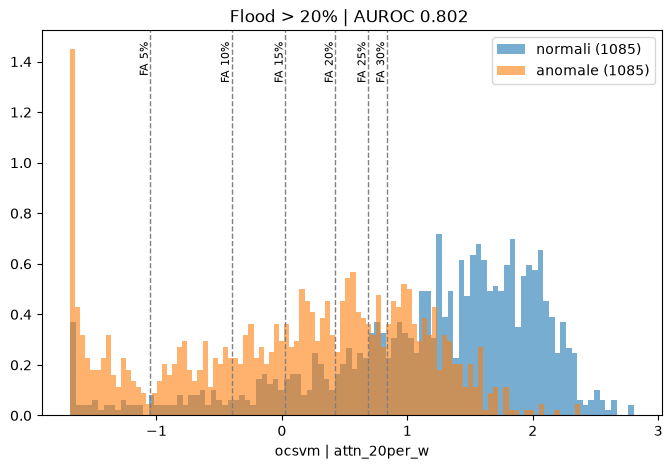

In [14]:
df = pd.read_csv(f"{RESULTS_DIR}/scores.csv")
score_normal = df[df.label == 0]['score']
score_anom = df[df.label == 1]['score']

lo, hi = np.quantile(df.score, [0.005, 0.995])                   
bins = np.linspace(lo, hi, 100)

plt.figure(figsize=(8, 5))
plt.hist(score_normal, bins=100, alpha=0.6, density=True, label=f"normali ({len(score_normal)})")
plt.hist(score_anom, bins=100, alpha=0.6, density=True, label=f"anomale ({len(score_anom)})")
for nome, r in results['rules'].items():                         
    if lo <= r["soglia"] <= hi:
        plt.axvline(x=r["soglia"], color='gray', linestyle='--', linewidth=1)
        plt.text(r["soglia"], plt.ylim()[1] * 0.97, nome.split("(")[-1].rstrip(")"), rotation=90, va="top", ha="right", fontsize=8)   
plt.xlabel(f"ocsvm | {job_name}")
plt.legend()
plt.title(f"Flood > {results['min_flood_area']:.0f}% | AUROC {results['auroc']:.3f} ")
plt.show()

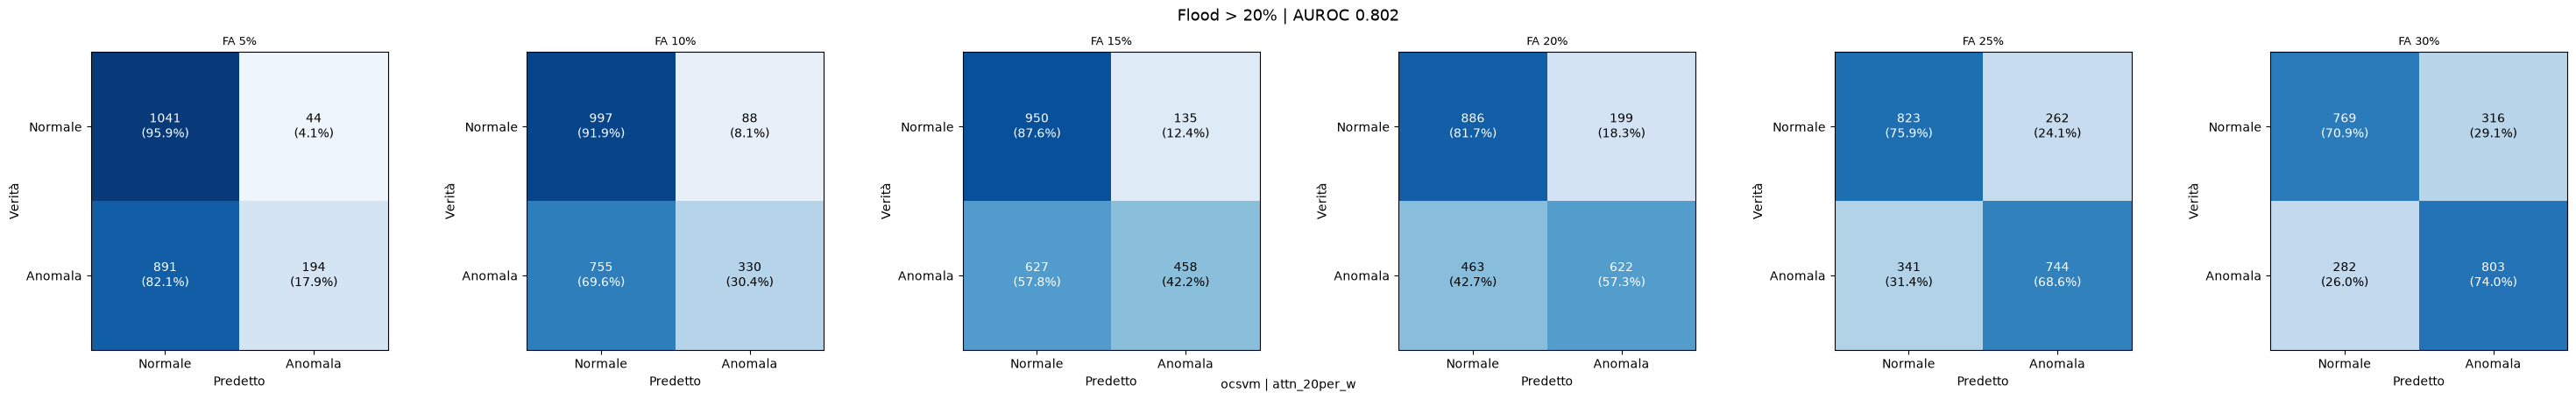

In [15]:
rules = results['rules']
fig, axes = plt.subplots(1, len(rules), figsize=(5 * len(rules), 4.5), squeeze=False)

for ax, (nome, r) in zip(axes[0], rules.items()):
    mat = np.array([[r["TN"], r["FP"]],
                     [r["FN"], r["TP"]]])
    mat_pct = mat / mat.sum(axis=1, keepdims=True) * 100

    im = ax.imshow(mat_pct, cmap="Blues", vmin=0, vmax=100)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Normale", "Anomala"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Normale", "Anomala"])
    ax.set_xlabel("Predetto"); ax.set_ylabel("Verità")
    ax.set_title(nome, fontsize=9)

    for i in range(2):
        for j in range(2):
            color = "white" if mat_pct[i, j] > 55 else "black"
            ax.text(j, i, f"{int(mat[i, j])}\n({mat_pct[i, j]:.1f}%)",
                    ha="center", va="center", color=color, fontsize=10)

fig.suptitle(f"Flood > {results['min_flood_area']:.0f}% | AUROC {results['auroc']:.3f}", fontsize=13)
fig.text(0.5, 0.01, f"ocsvm | {job_name}", ha="center", va="bottom", fontsize=10)              

plt.tight_layout()
plt.show()